# NLP Sentiment Classification on Customer Reviews

## 1. Introduction

This project focuses on classifying customer reviews into positive and negative sentiments using Natural Language Processing (NLP).

The workflow includes text preprocessing, TF-IDF feature extraction, model training, and evaluation.

Two machine learning algorithms are used:
- Multinomial Naive Bayes
- Logistic Regression

The final model will also be used to predict the sentiment of custom user-written reviews.

In [15]:
# Data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Text preprocessing
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Display settings
pd.set_option("display.max_colwidth", 100)

print("Libraries imported successfully!")

Libraries imported successfully!


In [16]:
# Load the sentiment reviews dataset
df = pd.read_csv("../data/sentiment_reviews.csv")

# Display dataset information
print("Dataset shape:", df.shape)
print("\nFirst 5 reviews:")
display(df.head())

print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

Dataset shape: (10, 3)

First 5 reviews:


,review_id,review_text,sentiment
0,1,"The product quality is exceptional, exceeded all my expectations!",positive
1,2,Terrible customer service and the item arrived completely damaged.,negative
2,3,"Average performance, decent for the price point but nothing special.",neutral
3,4,"Absolutely love this! Easy to setup, robust, and works flawlessly.",positive
4,5,Stopped working after two days. Extremely disappointed with the purchase.,negative



Sentiment distribution:
sentiment
positive    5
negative    4
neutral     1
Name: count, dtype: int64


In [17]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Check review lengths
df["review_length"] = df["review_text"].astype(str).apply(len)

print("\nReview length statistics:")
print(df["review_length"].describe())

Missing values:
review_id      0
review_text    0
sentiment      0
dtype: int64

Duplicate rows: 0

Review length statistics:
count    10.000000
mean     66.300000
std       4.321779
min      60.000000
25%      63.500000
50%      66.000000
75%      68.750000
max      73.000000
Name: review_length, dtype: float64


In [18]:
# Check the unique sentiment labels
print("Sentiment labels:", df["sentiment"].unique())

# Count each sentiment
print("\nSentiment counts:")
print(df["sentiment"].value_counts())

Sentiment labels: <StringArray>
['positive', 'negative', 'neutral']
Length: 3, dtype: str

Sentiment counts:
sentiment
positive    5
negative    4
neutral     1
Name: count, dtype: int64


In [19]:
# Load the larger customer reviews dataset
reviews_df = pd.read_csv("../data/womens_clothing_reviews.csv")

# Display dataset information
print("Dataset shape:", reviews_df.shape)

print("\nColumn names:")
print(reviews_df.columns.tolist())

print("\nFirst 5 rows:")
display(reviews_df.head())

Dataset shape: (23486, 11)

Column names:
['Unnamed: 0', 'Clothing ID', 'Age', 'Title', 'Review Text', 'Rating', 'Recommended IND', 'Positive Feedback Count', 'Division Name', 'Department Name', 'Class Name']

First 5 rows:


,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comfortable,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,"Love this dress! it's sooo pretty. i happened to find it in a store, and i'm glad i did bc i n...",5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and really wanted it to work for me. i initially ordered th...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, flirty, and fabulous! every time i wear it, i get no...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to the adjustable front tie. it is the perfect length t...,5,1,6,General,Tops,Blouses


In [20]:
# Check missing review text and ratings
print("Missing review texts:", reviews_df["Review Text"].isnull().sum())
print("Missing ratings:", reviews_df["Rating"].isnull().sum())

# Check rating distribution
print("\nRating distribution:")
print(reviews_df["Rating"].value_counts().sort_index())

Missing review texts: 845
Missing ratings: 0

Rating distribution:
Rating
1      842
2     1565
3     2871
4     5077
5    13131
Name: count, dtype: int64


In [21]:
# Remove rows with missing review text
reviews_df = reviews_df.dropna(subset=["Review Text"]).copy()

# Create sentiment labels from ratings
def assign_sentiment(rating):
    if rating <= 2:
        return "negative"
    elif rating == 3:
        return "neutral"
    else:
        return "positive"

reviews_df["sentiment"] = reviews_df["Rating"].apply(assign_sentiment)

# Keep only the columns needed for classification
reviews_df = reviews_df[["Review Text", "sentiment"]]

# Rename the review column
reviews_df = reviews_df.rename(columns={"Review Text": "review_text"})

# Display the cleaned dataset
print("Cleaned dataset shape:", reviews_df.shape)

print("\nSentiment distribution:")
print(reviews_df["sentiment"].value_counts())

display(reviews_df.head())

Cleaned dataset shape: (22641, 2)

Sentiment distribution:
sentiment
positive    17448
neutral      2823
negative     2370
Name: count, dtype: int64


,review_text,sentiment
0,Absolutely wonderful - silky and sexy and comfortable,positive
1,"Love this dress! it's sooo pretty. i happened to find it in a store, and i'm glad i did bc i n...",positive
2,I had such high hopes for this dress and really wanted it to work for me. i initially ordered th...,neutral
3,"I love, love, love this jumpsuit. it's fun, flirty, and fabulous! every time i wear it, i get no...",positive
4,This shirt is very flattering to all due to the adjustable front tie. it is the perfect length t...,positive


In [22]:
# Check duplicate reviews
print("Duplicate review texts:", reviews_df["review_text"].duplicated().sum())

# Check missing values after cleaning
print("\nMissing values:")
print(reviews_df.isnull().sum())

Duplicate review texts: 7

Missing values:
review_text    0
sentiment      0
dtype: int64


In [23]:
# Remove duplicate review texts
reviews_df = reviews_df.drop_duplicates(subset=["review_text"]).reset_index(drop=True)

# Check the final dataset
print("Final dataset shape:", reviews_df.shape)

print("\nSentiment distribution:")
print(reviews_df["sentiment"].value_counts())

Final dataset shape: (22634, 2)

Sentiment distribution:
sentiment
positive    17442
neutral      2823
negative     2369
Name: count, dtype: int64


In [24]:
# Download NLTK resources
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

print("NLTK resources downloaded successfully!")

NLTK resources downloaded successfully!


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\H\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\H\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\H\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [25]:
# Initialize stopwords and lemmatizer
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

# Define text preprocessing function
def clean_text(text):
    # Convert to lowercase
    text = text.lower()

    # Remove HTML tags
    text = re.sub(r"<.*?>", " ", text)

    # Remove punctuation and numbers
    text = re.sub(r"[^a-z\s]", " ", text)

    # Tokenize text
    words = text.split()

    # Remove stopwords and apply lemmatization
    words = [
        lemmatizer.lemmatize(word)
        for word in words
        if word not in stop_words
    ]

    return " ".join(words)

print("Text preprocessing function created successfully!")

Text preprocessing function created successfully!


In [26]:
# Compare original and cleaned reviews
for i in range(3):
    print("Original review:")
    print(reviews_df["review_text"].iloc[i])

    print("\nCleaned review:")
    print(clean_text(reviews_df["review_text"].iloc[i]))

    print("\n" + "-" * 70 + "\n")

Original review:
Absolutely wonderful - silky and sexy and comfortable

Cleaned review:
absolutely wonderful silky sexy comfortable

----------------------------------------------------------------------

Original review:
Love this dress!  it's sooo pretty.  i happened to find it in a store, and i'm glad i did bc i never would have ordered it online bc it's petite.  i bought a petite and am 5'8".  i love the length on me- hits just a little below the knee.  would definitely be a true midi on someone who is truly petite.

Cleaned review:
love dress sooo pretty happened find store glad bc never would ordered online bc petite bought petite love length hit little knee would definitely true midi someone truly petite

----------------------------------------------------------------------

Original review:
I had such high hopes for this dress and really wanted it to work for me. i initially ordered the petite small (my usual size) but i found this to be outrageously small. so small in fact th

In [27]:
# Apply text preprocessing to all reviews
reviews_df["cleaned_text"] = reviews_df["review_text"].apply(clean_text)

# Display original and cleaned reviews
display(reviews_df[["review_text", "cleaned_text", "sentiment"]].head())

print("Text preprocessing completed!")
print("Total processed reviews:", len(reviews_df))

,review_text,cleaned_text,sentiment
0,Absolutely wonderful - silky and sexy and comfortable,absolutely wonderful silky sexy comfortable,positive
1,"Love this dress! it's sooo pretty. i happened to find it in a store, and i'm glad i did bc i n...",love dress sooo pretty happened find store glad bc never would ordered online bc petite bought p...,positive
2,I had such high hopes for this dress and really wanted it to work for me. i initially ordered th...,high hope dress really wanted work initially ordered petite small usual size found outrageously ...,neutral
3,"I love, love, love this jumpsuit. it's fun, flirty, and fabulous! every time i wear it, i get no...",love love love jumpsuit fun flirty fabulous every time wear get nothing great compliment,positive
4,This shirt is very flattering to all due to the adjustable front tie. it is the perfect length t...,shirt flattering due adjustable front tie perfect length wear legging sleeveless pair well cardi...,positive


Text preprocessing completed!
Total processed reviews: 22634


In [28]:
# Select features and target
X = reviews_df["cleaned_text"]
y = reviews_df["sentiment"]

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining sentiment distribution:")
print(y_train.value_counts())

print("\nTesting sentiment distribution:")
print(y_test.value_counts())

Training samples: 18107
Testing samples: 4527

Training sentiment distribution:
sentiment
positive    13954
neutral      2258
negative     1895
Name: count, dtype: int64

Testing sentiment distribution:
sentiment
positive    3488
neutral      565
negative     474
Name: count, dtype: int64


In [29]:
# Initialize TF-IDF vectorizer
tfidf = TfidfVectorizer(max_features=5000)

# Fit on training data and transform both sets
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

# Display feature matrix information
print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)
print("Number of TF-IDF features:", len(tfidf.get_feature_names_out()))

Training TF-IDF shape: (18107, 5000)
Testing TF-IDF shape: (4527, 5000)
Number of TF-IDF features: 5000


In [30]:
# Train Multinomial Naive Bayes
nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

print("Multinomial Naive Bayes model trained successfully!")

Multinomial Naive Bayes model trained successfully!


In [31]:
# Train Logistic Regression
lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train_tfidf, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [32]:
# Generate predictions using both models
nb_predictions = nb_model.predict(X_test_tfidf)
lr_predictions = lr_model.predict(X_test_tfidf)

print("Predictions generated successfully!")

print("\nNaive Bayes sample predictions:")
print(nb_predictions[:10])

print("\nLogistic Regression sample predictions:")
print(lr_predictions[:10])

Predictions generated successfully!

Naive Bayes sample predictions:
['positive' 'positive' 'positive' 'positive' 'positive' 'positive'
 'positive' 'positive' 'positive' 'positive']

Logistic Regression sample predictions:
['positive' 'positive' 'positive' 'negative' 'neutral' 'positive'
 'positive' 'positive' 'positive' 'positive']


In [33]:
# Evaluate both models
models = {
    "Multinomial Naive Bayes": nb_predictions,
    "Logistic Regression": lr_predictions
}

for model_name, predictions in models.items():
    print(f"\n{model_name}")
    print("-" * 40)

    print("Accuracy:", accuracy_score(y_test, predictions))
    print("Precision:", precision_score(y_test, predictions, average="weighted"))
    print("Recall:", recall_score(y_test, predictions, average="weighted"))
    print("F1-score:", f1_score(y_test, predictions, average="weighted"))


Multinomial Naive Bayes
----------------------------------------
Accuracy: 0.781974817760106
Precision: 0.7625387176214672
Recall: 0.781974817760106
F1-score: 0.697306403273681

Logistic Regression
----------------------------------------
Accuracy: 0.8199690744422354
Precision: 0.7836942875816637
Recall: 0.8199690744422354
F1-score: 0.7928607431293265


In [34]:
# Detailed classification reports
print("Multinomial Naive Bayes:")
print(classification_report(y_test, nb_predictions))

print("\nLogistic Regression:")
print(classification_report(y_test, lr_predictions))

Multinomial Naive Bayes:
              precision    recall  f1-score   support

    negative       0.81      0.09      0.16       474
     neutral       0.60      0.02      0.03       565
    positive       0.78      1.00      0.88      3488

    accuracy                           0.78      4527
   macro avg       0.73      0.37      0.36      4527
weighted avg       0.76      0.78      0.70      4527


Logistic Regression:
              precision    recall  f1-score   support

    negative       0.63      0.41      0.50       474
     neutral       0.41      0.21      0.28       565
    positive       0.86      0.97      0.92      3488

    accuracy                           0.82      4527
   macro avg       0.64      0.53      0.56      4527
weighted avg       0.78      0.82      0.79      4527



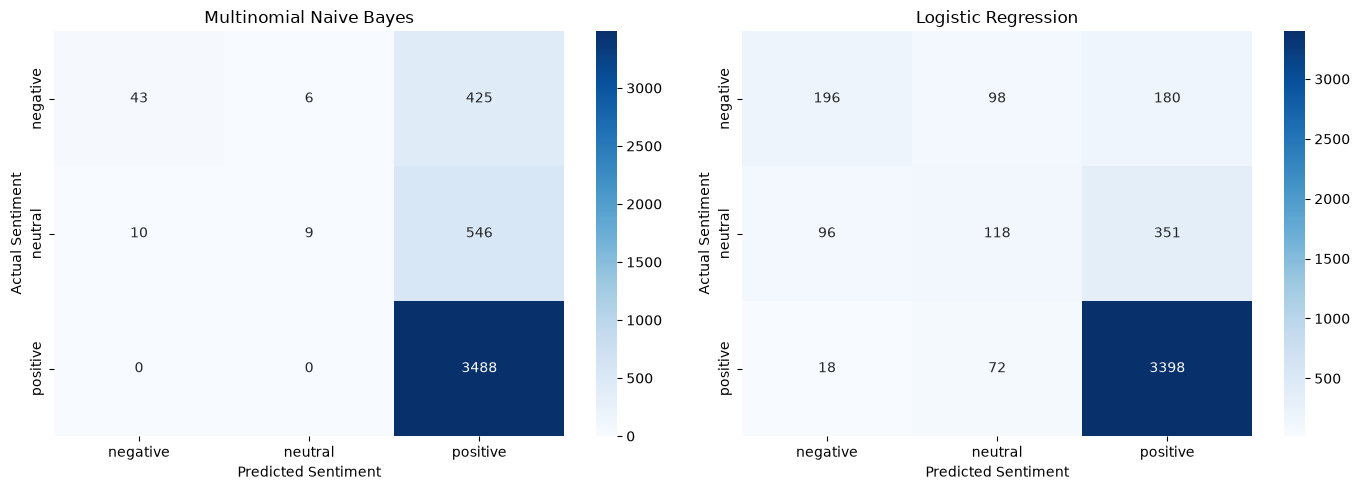

In [35]:
# Generate confusion matrices
nb_cm = confusion_matrix(y_test, nb_predictions, labels=["negative", "neutral", "positive"])
lr_cm = confusion_matrix(y_test, lr_predictions, labels=["negative", "neutral", "positive"])

# Plot both confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(nb_cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["negative", "neutral", "positive"],
            yticklabels=["negative", "neutral", "positive"],
            ax=axes[0])

axes[0].set_title("Multinomial Naive Bayes")
axes[0].set_xlabel("Predicted Sentiment")
axes[0].set_ylabel("Actual Sentiment")

sns.heatmap(lr_cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["negative", "neutral", "positive"],
            yticklabels=["negative", "neutral", "positive"],
            ax=axes[1])

axes[1].set_title("Logistic Regression")
axes[1].set_xlabel("Predicted Sentiment")
axes[1].set_ylabel("Actual Sentiment")

plt.tight_layout()
plt.show()

In [36]:
# Train Logistic Regression with balanced class weights
lr_balanced = LogisticRegression(max_iter=1000, class_weight="balanced")
lr_balanced.fit(X_train_tfidf, y_train)

# Generate predictions
lr_balanced_predictions = lr_balanced.predict(X_test_tfidf)

print("Balanced Logistic Regression trained successfully!")

Balanced Logistic Regression trained successfully!


In [37]:
# Train Logistic Regression with balanced class weights
balanced_lr_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

balanced_lr_model.fit(X_train_tfidf, y_train)

print("Balanced Logistic Regression trained successfully!")

Balanced Logistic Regression trained successfully!


In [38]:
# Make predictions using the balanced Logistic Regression model
balanced_lr_predictions = balanced_lr_model.predict(X_test_tfidf)

# Evaluate the model
print("Balanced Logistic Regression")
print("-" * 40)
print("Accuracy:", accuracy_score(y_test, balanced_lr_predictions))
print("Precision:", precision_score(y_test, balanced_lr_predictions, average="weighted"))
print("Recall:", recall_score(y_test, balanced_lr_predictions, average="weighted"))
print("F1-score:", f1_score(y_test, balanced_lr_predictions, average="weighted"))
print("Macro F1-score:", f1_score(y_test, balanced_lr_predictions, average="macro"))

Balanced Logistic Regression
----------------------------------------
Accuracy: 0.7631985862602165
Precision: 0.8195156736986333
Recall: 0.7631985862602165
F1-score: 0.7852831632880992
Macro F1-score: 0.5921762345414542


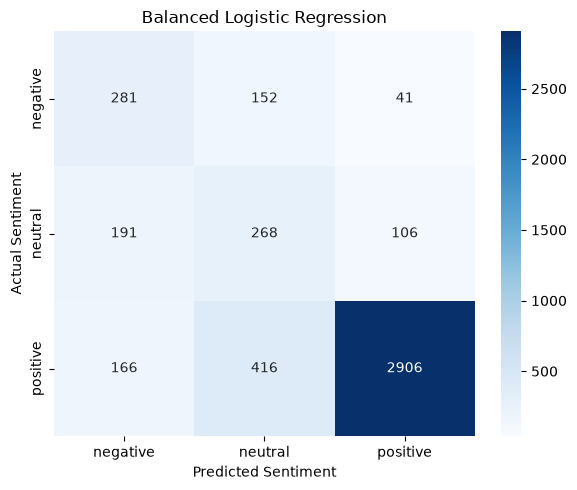

In [39]:
# Generate confusion matrix for balanced Logistic Regression
balanced_lr_cm = confusion_matrix(
    y_test,
    balanced_lr_predictions,
    labels=["negative", "neutral", "positive"]
)

# Plot confusion matrix
plt.figure(figsize=(6, 5))

sns.heatmap(
    balanced_lr_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["negative", "neutral", "positive"],
    yticklabels=["negative", "neutral", "positive"]
)

plt.title("Balanced Logistic Regression")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")

plt.tight_layout()
plt.show()

### Effect of Class Balancing

The balanced Logistic Regression model improved the classification
of negative and neutral reviews compared with the original model.
This was achieved by assigning balanced class weights during
training.

However, the model's performance on positive reviews decreased.
Overall accuracy also dropped, but the macro F1-score improved
from approximately 0.56 to 0.59, indicating better overall
performance across the three sentiment classes.

This experiment shows that class balancing can help address
the class imbalance in the dataset, although it introduces
a trade-off between overall accuracy and minority-class performance.

In [40]:
# Compare all three models

results = {
    "Model": [
        "Multinomial Naive Bayes",
        "Logistic Regression",
        "Balanced Logistic Regression"
    ],
    "Accuracy": [
        accuracy_score(y_test, nb_predictions),
        accuracy_score(y_test, lr_predictions),
        accuracy_score(y_test, balanced_lr_predictions)
    ],
    "Weighted F1": [
        f1_score(y_test, nb_predictions, average="weighted"),
        f1_score(y_test, lr_predictions, average="weighted"),
        f1_score(y_test, balanced_lr_predictions, average="weighted")
    ],
    "Macro F1": [
        f1_score(y_test, nb_predictions, average="macro"),
        f1_score(y_test, lr_predictions, average="macro"),
        f1_score(y_test, balanced_lr_predictions, average="macro")
    ]
}

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Weighted F1,Macro F1
0,Multinomial Naive Bayes,0.7820,0.6973,0.3573
1,Logistic Regression,0.8200,0.7929,0.5643
2,Balanced Logistic Regression,0.7632,0.7853,0.5922


In [41]:
# Function to predict sentiment of new reviews

def predict_sentiment(text):
    cleaned_review = clean_text(text)
    review_tfidf = tfidf.transform([cleaned_review])
    prediction = balanced_lr_model.predict(review_tfidf)[0]

    return prediction

print("Prediction function created successfully!")

Prediction function created successfully!


In [42]:
# Test the prediction function with sample reviews

test_reviews = [
    "I absolutely love this product, it works perfectly!",
    "The product is okay, nothing special.",
    "Terrible quality and very disappointing."
]

for review in test_reviews:
    print("Review:", review)
    print("Predicted sentiment:", predict_sentiment(review))
    print("-" * 50)

Review: I absolutely love this product, it works perfectly!
Predicted sentiment: positive
--------------------------------------------------
Review: The product is okay, nothing special.
Predicted sentiment: neutral
--------------------------------------------------
Review: Terrible quality and very disappointing.
Predicted sentiment: negative
--------------------------------------------------


In [43]:
# Interactive sentiment prediction

review = input("Enter a customer review: ")

predicted_sentiment = predict_sentiment(review)

print("\nPredicted sentiment:", predicted_sentiment)


Predicted sentiment: negative


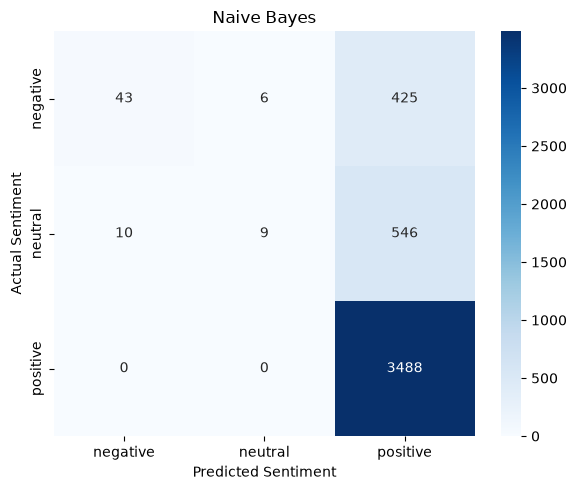

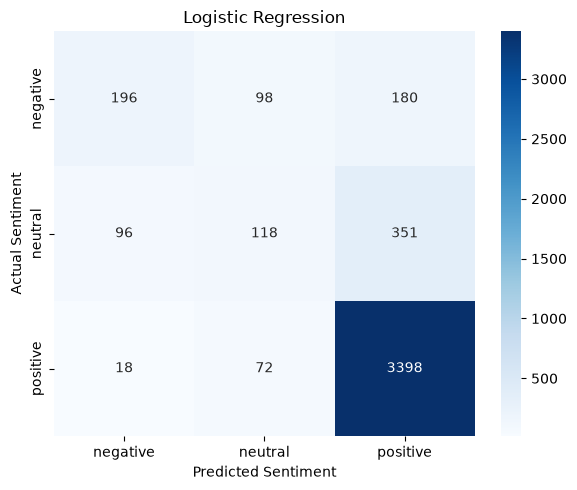

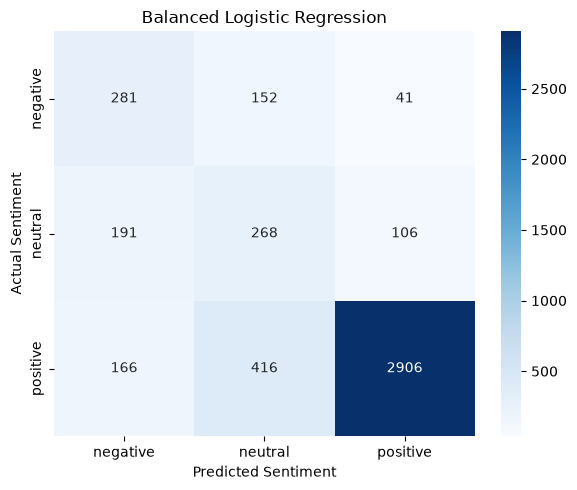

All confusion matrices saved successfully!


In [44]:
import os

# Create outputs folder if it does not exist
os.makedirs("../outputs", exist_ok=True)

labels = ["negative", "neutral", "positive"]

models_to_save = {
    "Naive_Bayes": nb_predictions,
    "Logistic_Regression": lr_predictions,
    "Balanced_Logistic_Regression": balanced_lr_predictions
}

for model_name, predictions in models_to_save.items():

    cm = confusion_matrix(y_test, predictions, labels=labels)

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=labels,
        yticklabels=labels
    )

    plt.title(model_name.replace("_", " "))
    plt.xlabel("Predicted Sentiment")
    plt.ylabel("Actual Sentiment")
    plt.tight_layout()

    plt.savefig(f"../outputs/{model_name}_confusion_matrix.png", dpi=300)
    plt.show()
    plt.close()

print("All confusion matrices saved successfully!")

In [ ]:
# Save model comparison results
results_df.to_csv(
    "../outputs/model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")